In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [41]:
df=pd.read_csv('/content/sample_data/credit_risk_dataset.csv')

In [42]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


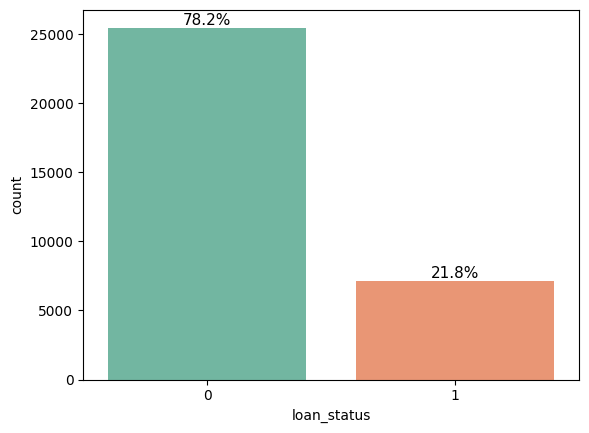

In [43]:
ax = sns.countplot(x='loan_status', data=df, palette='Set2', hue='loan_status', legend=False)
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom', fontsize=11)
plt.show()

In [44]:
numerical_cols=df.select_dtypes(include=np.number).columns
numerical_cols

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='object')

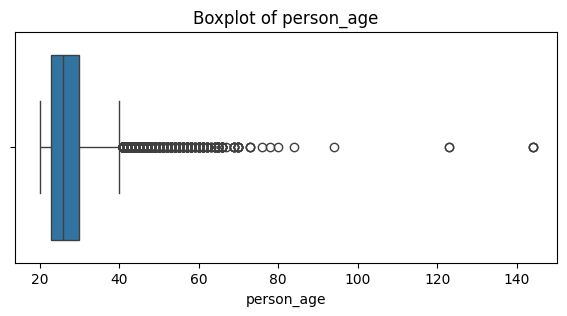

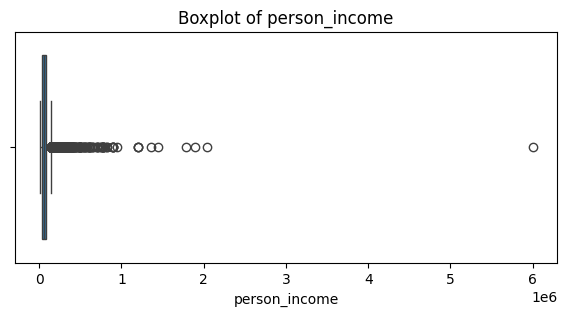

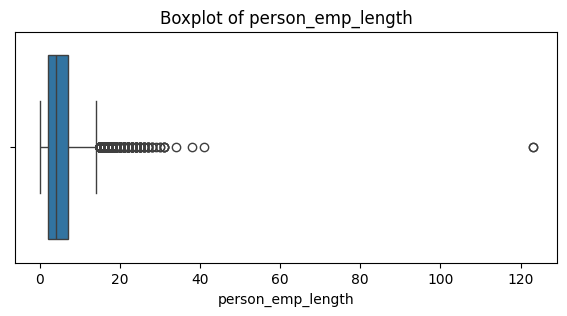

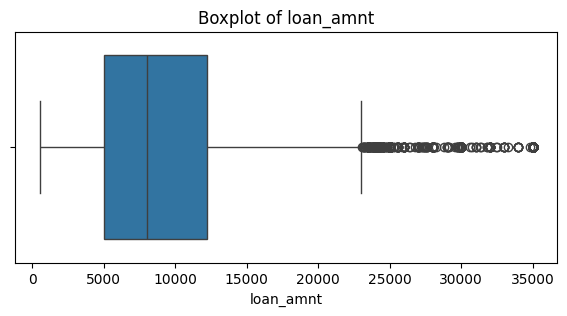

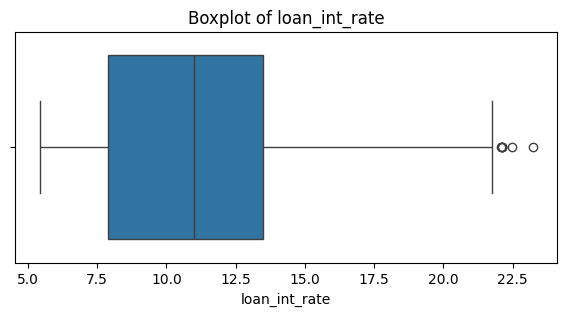

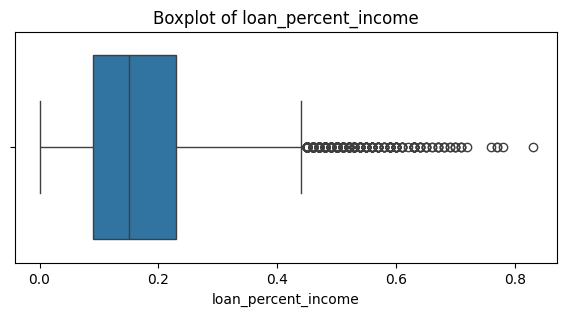

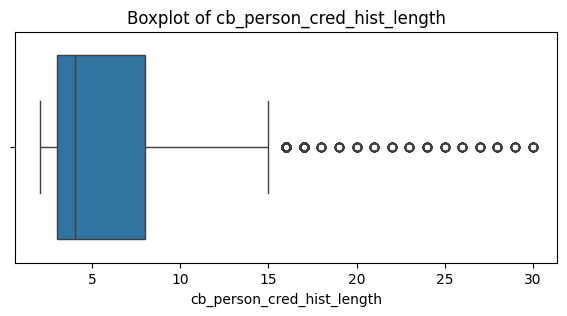

In [45]:
for col in numerical_cols:
    if col != 'loan_status':
        plt.figure(figsize=(7, 3))
        sns.boxplot(x=df[col])
        plt.title(f'Boxplot of {col}')
        plt.show()

In [46]:
numeric_features = df.select_dtypes(
    include=np.number
).columns.drop('loan_status')

outlier_summary = []

for col in numeric_features:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df.loc[
        (df[col] < lower_bound) |
        (df[col] > upper_bound),
        col
    ]

    outlier_summary.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': outliers.count(),
        'Outlier Percentage': (
            outliers.count() / df[col].notna().sum()
        ) * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,person_age,12.500,40.500,1494,4.585495
1,person_income,-22550.000,140250.000,1484,4.554802
2,person_emp_length,-5.500,14.500,853,2.692041
3,loan_amnt,-5800.000,23000.000,1689,5.184003
4,loan_int_rate,-0.455,21.825,6,0.020363
5,loan_percent_income,-0.120,0.440,651,1.998097
6,cb_person_cred_hist_length,-4.500,15.500,1142,3.505110


<Axes: >

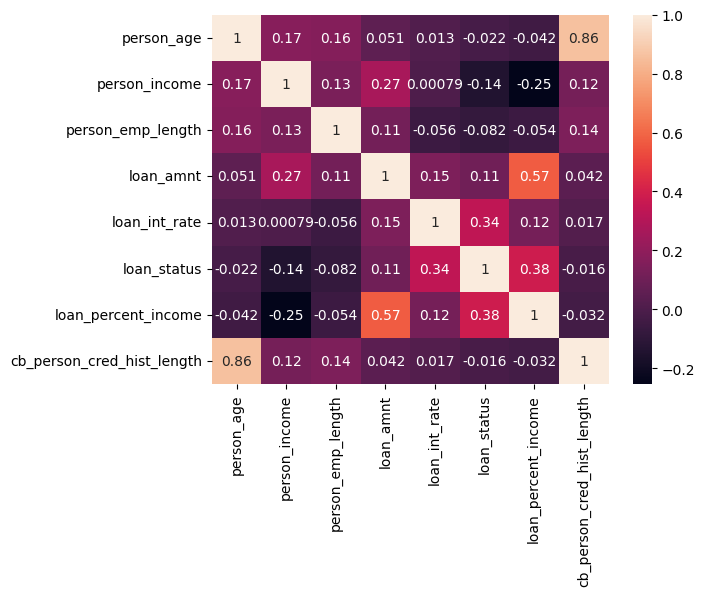

In [47]:
sns.heatmap(df.corr(numeric_only=True), annot=True)


In [48]:
missing=df.isnull().sum()
missing_percent=(missing/len(df))*100
missing_df=pd.DataFrame({'missing':missing, 'missing_percent':missing_percent})
missing_df=missing_df[missing_df['missing']>0]
missing_df

,missing,missing_percent
person_emp_length,895,2.747000
loan_int_rate,3116,9.563856


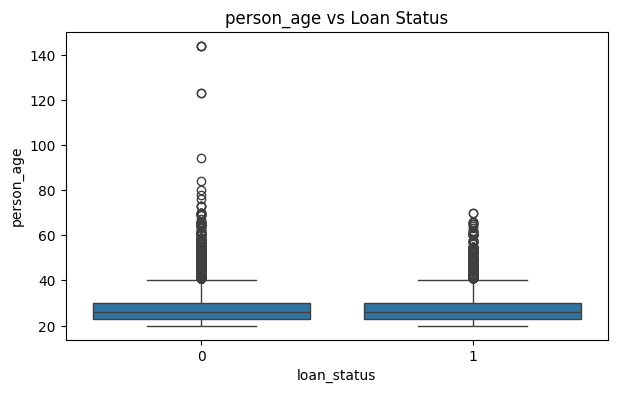

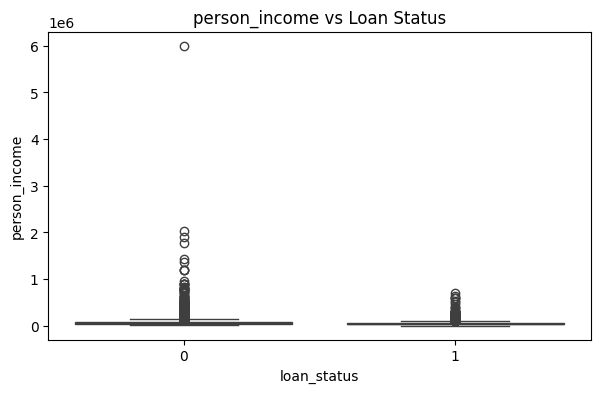

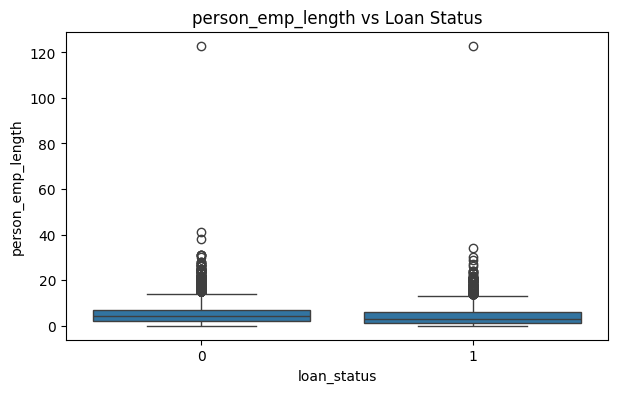

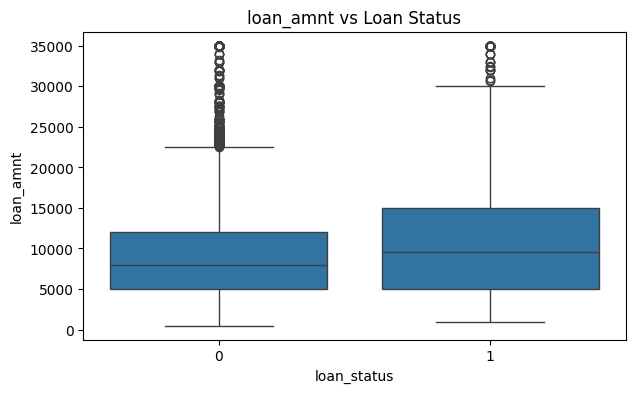

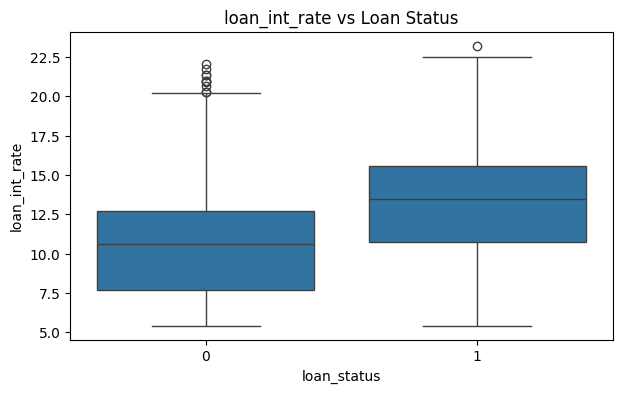

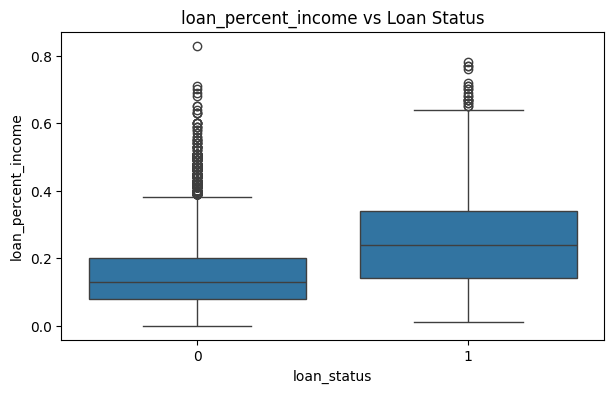

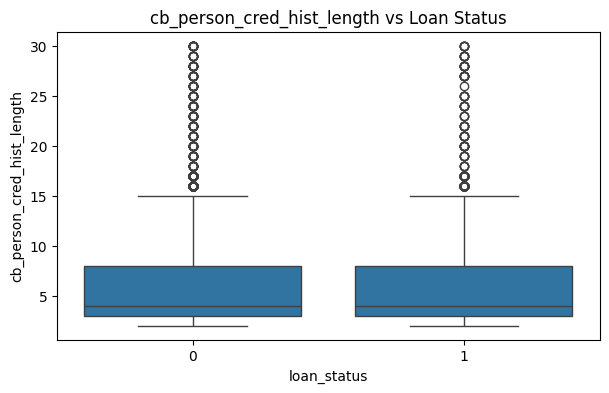

In [49]:
numerical_cols = df.select_dtypes(
    include=np.number
).columns

for col in numerical_cols:
    if col != 'loan_status':
        plt.figure(figsize=(7, 4))

        sns.boxplot(
            data=df,
            x='loan_status',
            y=col
        )

        plt.title(f'{col} vs Loan Status')
        plt.show()


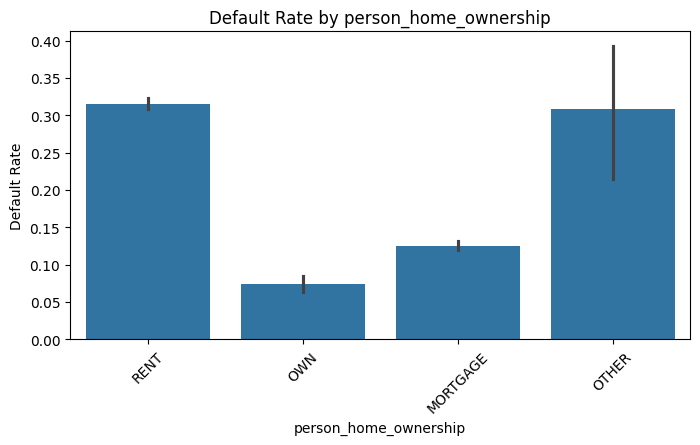

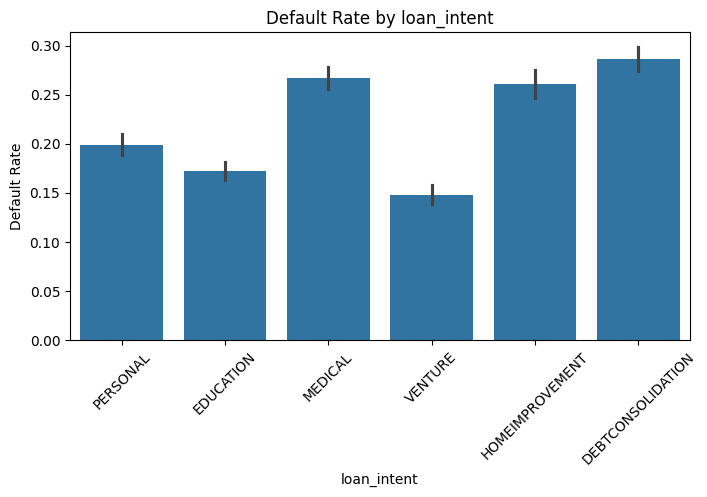

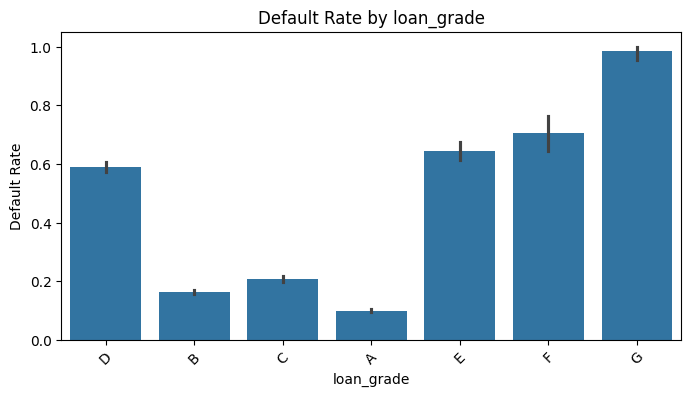

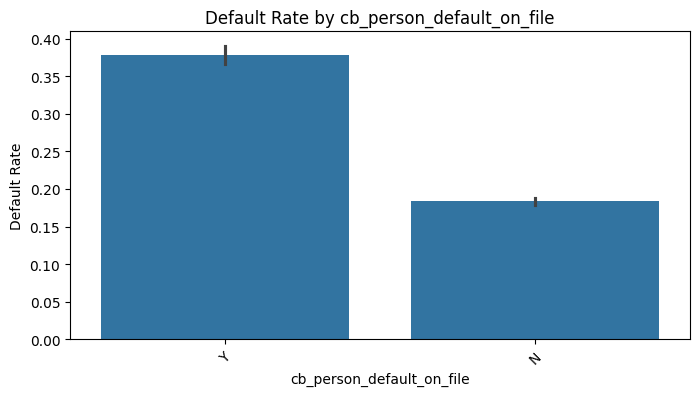

In [50]:
categorical_cols = df.select_dtypes(
    include='object'
).columns

for col in categorical_cols:
    plt.figure(figsize=(8, 4))

    sns.barplot(
        data=df,
        x=col,
        y='loan_status'
    )

    plt.title(f'Default Rate by {col}')
    plt.ylabel('Default Rate')
    plt.xticks(rotation=45)

    plt.show()

In [51]:
for col in categorical_cols:
    print(f"\nCounts for {col}:")
    print(df[col].value_counts())


Counts for person_home_ownership:
person_home_ownership
RENT        16446
MORTGAGE    13444
OWN          2584
OTHER         107
Name: count, dtype: int64

Counts for loan_intent:
loan_intent
EDUCATION            6453
MEDICAL              6071
VENTURE              5719
PERSONAL             5521
DEBTCONSOLIDATION    5212
HOMEIMPROVEMENT      3605
Name: count, dtype: int64

Counts for loan_grade:
loan_grade
A    10777
B    10451
C     6458
D     3626
E      964
F      241
G       64
Name: count, dtype: int64

Counts for cb_person_default_on_file:
cb_person_default_on_file
N    26836
Y     5745
Name: count, dtype: int64


In [52]:
df_copy=df.copy()

In [53]:

print("Original rows:", len(df_copy))

# 1. Remove duplicates
df_copy = df_copy.drop_duplicates()

# 2. Validate age
df_copy = df_copy[
    df_copy['person_age'].between(18, 100)
]

# 3. Validate employment length
df_copy = df_copy[
    df_copy['person_emp_length'].isna() |
    (
        (df_copy['person_emp_length'] <= df_copy['person_age']) &
        (df_copy['person_emp_length'] <= 60)
    )
]

# 4. Validate income and loan amount
df_copy = df_copy[
    (df_copy['person_income'] > 0) &
    (df_copy['loan_amnt'] > 0)
]

print("Rows after cleaning:", len(df_copy))
print("Remaining missing values:")
print(df_copy.isnull().sum())

Original rows: 32581
Rows after cleaning: 32409
Remaining missing values:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              887
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3094
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64


In [54]:
X=df_copy.drop('loan_status',axis=1)
y=df_copy['loan_status']

In [55]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y)
print("Training_features:",X_train.shape)
print("Testing_features:",X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))
print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

#normalize=True means show the values as proportions (percentages) instead of actual counts.


Training_features: (25927, 11)
Testing_features: (6482, 11)

Training target distribution:
loan_status
0    0.781309
1    0.218691
Name: proportion, dtype: float64

Testing target distribution:
loan_status
0    0.78124
1    0.21876
Name: proportion, dtype: float64


**Step 2: Identify numerical and categorical columns.**

In [56]:
numeric_cols=X_train.select_dtypes(include=['int64','float64']).columns
categorical_colus=X_train.select_dtypes(include=['object']).columns
print("Numerical columns:",numeric_cols)
print("\nCategorical columns:",categorical_colus)

Numerical columns: Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')

Categorical columns: Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='object')


**Handle class imbalance**

In [57]:
neg,pos=np.bincount(y_train)
scale_weights=neg/pos
print("Non-default cases:",neg)
print("Default cases:",pos)
print("Class weight:", scale_weights)

#scale_weights = 3.57 means the default class (1) is given approximately 3.57 times more weight than the non-default class (0) during XGBoost training.


Non-default cases: 20257
Default cases: 5670
Class weight: 3.572663139329806


**Data preprocessing**

In [58]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [59]:
preprocessor_lr=ColumnTransformer(
    transformers=[
        ('num',Pipeline(steps=[
            ('imputer',SimpleImputer(strategy='mean')),
            ('scaler',StandardScaler())
        ]),numeric_cols),
        ('cat',Pipeline(steps=[
            ('imputer',SimpleImputer(strategy='constant',fill_value='missing')),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),categorical_colus)
    ]
)

In [60]:
preprocessor_xg = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='mean'))
        ]), numeric_cols),

        ('cat', Pipeline(steps=[
            ('imputer', SimpleImputer(
                strategy='constant',
                fill_value='missing'
            )),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_colus)
    ]
)

**Create the Logistic Regression model pipeline**

In [61]:
from sklearn.linear_model import LogisticRegression

lr_pipeline=Pipeline(steps=[
    ('preprocessor',preprocessor_lr),
    ('classifier',LogisticRegression(random_state=42,class_weight='balanced',max_iter=1000))

])

**create the XGboost model pipeline**

In [62]:
from xgboost import XGBClassifier
xg_pipeline=Pipeline(steps=[
    ('preprocessor',preprocessor_xg),
    ('classifier',XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.1,
        scale_pos_weight=scale_weights,
        random_state=42,
        eval_metrics='logloss'))])

**Parameter	Meaning**

n_estimators=300	Builds 300 decision trees

max_depth=3	Each tree can grow up to 3 levels deep

learning_rate=0.1	Controls how much each new tree contributes

scale_pos_weight=scale_weights	Gives additional importance to default cases

random_state=42	Helps make results reproducible

eval_metric='logloss'	Specifies the loss metric used during training

**Set up Stratified Cross-Validation**

In [63]:
from sklearn.model_selection import StratifiedKFold
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)


**What each setting means:**
- n_splits=5: creates 5 folds.
- shuffle=True: shuffles the rows before splitting.
- random_state=42: makes the split reproducible.

**Define the evaluation metrics**

In [64]:
scoring = {
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

**Perform cross-validation for both models**

In [65]:
from sklearn.model_selection import cross_validate

#logistic regression cross validation
cv_results_lr=cross_validate(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

#XGBoost cross validation
cv_results_xg=cross_validate(
    xg_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [66]:
cv_results_lr

{'fit_time': array([0.34225488, 0.58442354, 0.48488665, 0.56478238, 0.4465239 ]),
 'score_time': array([0.07466221, 0.1531117 , 0.15560722, 0.15291429, 0.06919861]),
 'test_roc_auc': array([0.87658238, 0.87441109, 0.87084688, 0.86536562, 0.86400314]),
 'test_accuracy': array([0.81623602, 0.81739298, 0.81195757, 0.80867888, 0.80559306]),
 'test_precision': array([0.55709779, 0.55921469, 0.54984326, 0.54443054, 0.53850856]),
 'test_recall': array([0.77865961, 0.77865961, 0.77336861, 0.76719577, 0.77689594]),
 'test_f1': array([0.64950349, 0.65093992, 0.64272627, 0.63689605, 0.63610108])}

**Calculate the average cross-validation scores**

In [67]:
#calculate average score for logistic regression
lr_scores=pd.DataFrame(cv_results_lr).mean()


#calculate average score for xgboost
xg_scores=pd.DataFrame(cv_results_xg).mean()

#combine both models into one comparision table
cv_comparision=pd.DataFrame({'Logistic Regression':lr_scores,'XGBoost':xg_scores})


#keep only evalution metrics
cv_comparision=cv_comparision.loc[['test_roc_auc', 'test_accuracy', 'test_precision',
     'test_recall', 'test_f1']
]

#display with cleaner metric names
cv_comparision.index=['ROC AUC','Accuracy','Precision','Recall','F1']

print(cv_comparision.round(4))

           Logistic Regression  XGBoost
ROC AUC                 0.8702   0.9400
Accuracy                0.8120   0.9021
Precision               0.5498   0.7671
Recall                  0.7750   0.7931
F1                      0.6432   0.7799


1. ROC-AUC – How well can the model distinguish risky customers?
Your results
Logistic Regression
0.8702


XGBoost
0.9400



What does ROC-AUC actually mean?
Imagine a bank receives loan applications from 100 customers.

Some customers will repay their loans, while others may default.

Our model gives each customer a probability of default.

For example:
Customer	Actual result	Predicted default probability
A	Default	90%
B	No default	15%
C	Default	80%
D	No default	25%

A good model should generally assign:
- Higher default probabilities to customers who actually default.
- Lower default probabilities to customers who don't default.
ROC-AUC measures how well the model ranks defaulting customers above non-defaulting customers across different classification thresholds.

How do we interpret the scores?
- 0.5: No better than random ranking.
- 0.7–0.8: Acceptable discrimination.
- 0.8–0.9: Good discrimination.
- Above 0.9: Excellent discrimination.
These are common rules of thumb, not strict boundaries.

Your result:
- Logistic Regression: 0.8702 – good ability to distinguish the two groups.
- XGBoost: 0.9400 – excellent ability to distinguish the two groups.
XGBoost has better ranking ability in your cross-validation results.
2. Accuracy – How many predictions are correct?
Your results
Logistic Regression
81.20%


XGBoost
90.21%



Accuracy measures the percentage of predictions that are correct.

Imagine the model predicts the loan status of 100 customers.
- 90 predictions are correct.
- 10 predictions are incorrect.
Then accuracy is 90%.

The formula is:
\[
Accuracy=\frac{Correct\ Predictions}{Total\ Predictions}
\]

Why can accuracy be misleading in credit risk?
Your dataset has an imbalance:
- Approximately 78% customers do not default.
- Approximately 22% customers default.
Imagine a model that predicts every customer as a non-defaulter.

It would achieve approximately 78% accuracy, even though it fails to identify every actual defaulter!

This is why we don't judge a credit risk model using accuracy alone.

Your result: XGBoost achieves 90.21% accuracy, compared with Logistic Regression's 81.20%.

That's a considerable improvement, but we also need to examine precision and recall.
3. Precision – When the model predicts default, how often is it correct?
Your results
Logistic Regression
54.98%


XGBoost
76.71%



This is one of the most important metrics to understand.

Imagine a bank's model examines 100 loan applicants and predicts that 100 of them will default.

But after checking their actual repayment behaviour:
- 55 actually defaulted.
- 45 did not default.
The model raised 45 false alarms.

Its precision would be 55%.
Let's understand the four prediction outcomes
Actual vs predicted loan status
TP
True Positive

Predicted default, and customer actually defaults.


FP
False Positive

Predicted default, but customer does not default.


TN
True Negative

Predicted no default, and customer does not default.


FN
False Negative

Predicted no default, but customer actually defaults.




Precision mainly considers TP and FP.
\[
Precision=\frac{TP}{TP+FP}
\]

What does your result mean?
Model	Precision
Logistic Regression	54.98%
XGBoost	76.71%

If both models flag 100 customers as potential defaulters:
- Logistic Regression: approximately 55 are actual defaulters.
- XGBoost: approximately 77 are actual defaulters.
XGBoost produces fewer false alarms among the customers it flags.

This is a significant improvement.
4. Recall – How many actual defaulters did the model identify?
Your results
Logistic Regression
77.50%


XGBoost
79.31%



Recall is different from precision.

Precision starts with customers the model predicted would default.

Recall starts with customers who actually defaulted.

Imagine there are 100 customers who actually default.

The model identifies:
- 78 customers correctly.
- Misses 22 customers.
Those 22 are false negatives.

The formula is:
\[
Recall=\frac{TP}{TP+FN}
\]

What does your result mean?
Model	Recall
Logistic Regression	77.50%
XGBoost	79.31%

Out of 100 actual defaulters:
- Logistic Regression identifies approximately 78.
- XGBoost identifies approximately 79.
XGBoost is slightly better at identifying actual defaulters.
Why is recall important for a bank?
Suppose a bank approves a loan for a customer who is likely to default.

That can result in financial losses.

A higher recall means the model catches more customers who may default.

However, increasing recall can sometimes also increase false alarms. That's why we consider precision alongside it.
5. F1-score – How well does the model balance precision and recall?
Your results
Logistic Regression
0.6432


XGBoost
0.7799



Let's say we have two models:
Model	Precision	Recall
Model A	90%	30%
Model B	75%	75%

Model A has high precision, but it misses many actual defaulters.

Model B has a better balance between precision and recall.

F1-score helps us evaluate this balance.

The formula is:
\[
F1=2\times\frac{Precision\times Recall}{Precision+Recall}
\]

It uses the harmonic mean, which means a very low precision or recall can pull the F1-score down significantly.

Your result:
- Logistic Regression: 0.6432
- XGBoost: 0.7799
XGBoost has a better balance between identifying defaulters and avoiding false alarms.

One interview point to remember: In credit risk prediction, recall is important because missing a potential defaulter can be costly. Precision is also important because incorrectly flagging reliable customers can lead to rejected or unnecessarily restricted loans. The right balance depends on the bank's risk tolerance and business costs.

Your current cross-validation results indicate that XGBoost is the stronger model.

The most notable improvement is precision: from 54.98% to 76.71%. It also improves ROC-AUC from 0.8702 to 0.9400.

**Train both models using the fitting data**


In [68]:
#training logistic regression
lr_pipeline.fit(X_train,y_train)

#training xgboost
xg_pipeline.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [05:49:28] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='c...
                               eval_metrics='logloss', feature_types=None,
                               feature_weights=None, gamma=None,
                               grow_policy=None, importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=3, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=None, ...))])

**Evaluate both models on the validation data*

In [69]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Fitting data shape:", X_fit.shape)
print("Validation data shape:", X_val.shape)

print("\nFitting target distribution:")
print(y_fit.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))

Fitting data shape: (20741, 11)
Validation data shape: (5186, 11)

Fitting target distribution:
loan_status
0    0.781303
1    0.218697
Name: proportion, dtype: float64

Validation target distribution:
loan_status
0    0.781334
1    0.218666
Name: proportion, dtype: float64


Then why did I create another split?
This is the important part.

After the first split, we have 80% training data and 20% testing data.

But during model development, we need to make decisions:
- Which model performs better?
- Which XGBoost settings are better?
- Which prediction threshold should we use?
If we repeatedly use our testing data to make these decisions, we are indirectly using the test results to influence our model.

Then the final test result may no longer be a fair measure of performance.

So we divide the 80% training data one more time.

In [70]:
# Logistic Regression predictions
y_pred_lr = lr_pipeline.predict(X_val)

# XGBoost predictions
y_pred_xg = xg_pipeline.predict(X_val)

print("Logistic Regression predictions:")
print(y_pred_lr[:10])

print("\nActual loan status:")
print(y_val.iloc[:10].values)

print("\nXGBoost predictions:")
print(y_pred_xg[:10])

Logistic Regression predictions:
[0 0 0 0 0 0 0 0 0 0]

Actual loan status:
[0 0 0 0 0 1 0 1 0 0]

XGBoost predictions:
[0 0 0 0 0 1 0 0 1 0]


**Calculate validation performance**

In [71]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Logistic Regression evaluation
lr_val_metrics = {
    'Accuracy': accuracy_score(y_val, y_pred_lr),
    'Precision': precision_score(y_val, y_pred_lr),
    'Recall': recall_score(y_val, y_pred_lr),
    'F1-score': f1_score(y_val, y_pred_lr),
    'ROC-AUC': roc_auc_score(
        y_val,
        lr_pipeline.predict_proba(X_val)[:, 1]
    )
}

# XGBoost evaluation
xg_val_metrics = {
    'Accuracy': accuracy_score(y_val, y_pred_xg),
    'Precision': precision_score(y_val, y_pred_xg),
    'Recall': recall_score(y_val, y_pred_xg),
    'F1-score': f1_score(y_val, y_pred_xg),
    'ROC-AUC': roc_auc_score(
        y_val,
        xg_pipeline.predict_proba(X_val)[:, 1]
    )
}

# Compare both models
val_comparison = pd.DataFrame({
    'Logistic Regression': lr_val_metrics,
    'XGBoost': xg_val_metrics
})

print(val_comparison.round(4))

           Logistic Regression  XGBoost
Accuracy                0.8205   0.9146
Precision               0.5660   0.8049
Recall                  0.7681   0.8042
F1-score                0.6517   0.8046
ROC-AUC                 0.8698   0.9555


**Understand the confusion matrix
Before tuning XGBoost, let's understand exactly what kinds of mistakes it makes.**

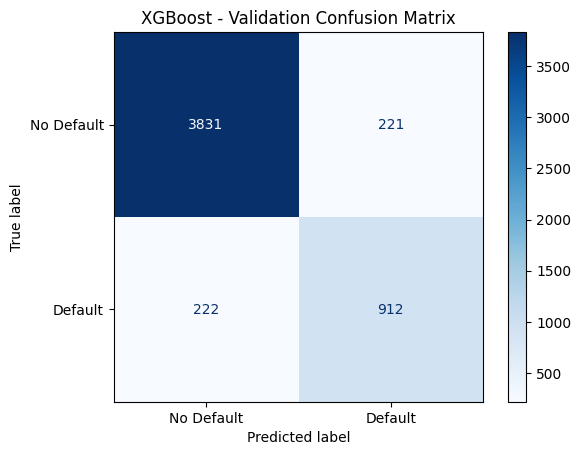

In [72]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix for XGBoost
cm = confusion_matrix(y_val, y_pred_xg)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Default', 'Default']
)

disp.plot(cmap='Blues')

plt.title("XGBoost - Validation Confusion Matrix")
plt.show()

Understand each number in your project
A. True Negative = 3,831

The model predicted that 3,831 customers would not default.

Their actual loan status was also no default.

This means the model correctly identified 3,831 reliable customers.

B. False Positive = 221

The model predicted that 221 customers would default.

However, these customers actually did not default.

In a real bank, these are potential false alarms. The bank might unnecessarily consider reliable customers risky.

C. False Negative = 222

The model predicted that 222 customers would not default.

However, they actually defaulted.

This is an important mistake in credit risk prediction because the model failed to identify these risky customers.

D. True Positive = 912

The model predicted that 912 customers would default.

And all 912 actually defaulted.

This means the model successfully identified 912 risky customers.

**What does this tell us about XGBoost?**
Your model:
- Correctly identified 3,831 non-defaulters.
- Correctly identified 912 defaulters.
- Incorrectly flagged 221 non-defaulters.
- Missed 222 actual defaulters.
The two mistakes we need to pay attention to are:
1. False positives: Reliable customers incorrectly identified as risky.
2. False negatives: Risky customers incorrectly identified as reliable.

**Prepare XGBoost hyperparameter tuning**

In [73]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'classifier__n_estimators': [200, 300, 400, 500],
    'classifier__max_depth': [2, 3, 4, 5],
    'classifier__learning_rate': [0.03, 0.05, 0.1, 0.15],
    'classifier__subsample': [0.8, 0.9, 1.0],
    'classifier__colsample_bytree': [0.8, 0.9, 1.0],
    'classifier__min_child_weight': [1, 3, 5]
}

**Configure RandomizedSearchCV**
We are telling Python:
- Which model to tune: xg_pipeline.
- Which parameters to experiment with: param_grid.
- How many combinations to try: 20.
- How to evaluate each combination: 5-fold cross-validation.
- Which metric to prioritize: ROC-AUC.

In [77]:
random_search = RandomizedSearchCV(
    estimator=xg_pipeline,
    param_distributions=param_grid,
    n_iter=20,
    scoring='roc_auc',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

Python will:
1. Select 20 random hyperparameter combinations.
2. Train each combination using 5-fold cross-validation.
3. Calculate ROC-AUC for each fold.
4. Calculate the average ROC-AUC for each combination.
5. Identify the combination with the highest average ROC-AUC.


In [78]:
random_search.fit(X_fit, y_fit)

print("Hyperparameter tuning completed!")

Fitting 5 folds for each of 20 candidates, totalling 100 fits


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [05:51:07] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Hyperparameter tuning completed!


**Find the best hyperparameters**

In [79]:
print("Best Hyperparameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(random_search.best_score_)

Best Hyperparameters:
{'classifier__subsample': 1.0, 'classifier__n_estimators': 300, 'classifier__min_child_weight': 3, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.1, 'classifier__colsample_bytree': 0.8}

Best Cross-Validation ROC-AUC:
0.9447149260826444


**Create the best model**

In [80]:
best_model = random_search.best_estimator_

print("Best XGBoost model created successfully!")
print(best_model)

Best XGBoost model created successfully!
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='c...
                               eval_metrics='logloss', feature_types=None,
                               feature_weights=None, gamma=None,
      

**Evaluate the tuned XGBoosmodel**
Now let's check whether tuning improved the model's performance on our validation dataset.

In [81]:
# Predict loan status
y_pred_best = best_model.predict(X_val)

# Predict default probabilities
y_prob_best = best_model.predict_proba(X_val)[:, 1]

print("Tuned XGBoost predictions:")
print(y_pred_best[:10])

print("\nActual loan status:")
print(y_val.iloc[:10].values)

print("\nDefault probabilities:")
print(y_prob_best[:10])

Tuned XGBoost predictions:
[0 0 0 0 0 1 0 0 0 0]

Actual loan status:
[0 0 0 0 0 1 0 1 0 0]

Default probabilities:
[0.05005262 0.00084273 0.21797909 0.03794355 0.05702744 0.83964086
 0.01186407 0.07052047 0.47671548 0.00891426]


Why did Customer 8 get prediction 0?
Look at Customer 8:
- Actual status: 1 (default).
- Predicted probability: 0.0705 (approximately 7.05%).
- Predicted status: 0 (no default).
Our current classification threshold is 0.5.

The model predicted default only when the probability was at least 50%.

Since 7.05% is below 50%, it predicted no default.

This is how a false negative happens: the model assigned a low probability to a customer who actually defaulted.

**Calculate tuned model validation metrics**

In [82]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

best_val_metrics = {
    'Accuracy': accuracy_score(y_val, y_pred_best),
    'Precision': precision_score(y_val, y_pred_best),
    'Recall': recall_score(y_val, y_pred_best),
    'F1-score': f1_score(y_val, y_pred_best),
    'ROC-AUC': roc_auc_score(y_val, y_prob_best)
}

print(pd.Series(best_val_metrics).round(4))

Accuracy     0.9180
Precision    0.8220
Recall       0.7981
F1-score     0.8098
ROC-AUC      0.9495
dtype: float64


Why are we doing this?

We want to compare:
- Original XGBoost validation performance.
- Tuned XGBoost validation performance.

What have we learned?
Hyperparameter tuning does not guarantee improvement in every metric.

In your case, tuning improved precision and F1-score but slightly reduced recall and ROC-AUC.

This is a useful observation to discuss in interviews.

**Plot the tuned model's confusion matrix**

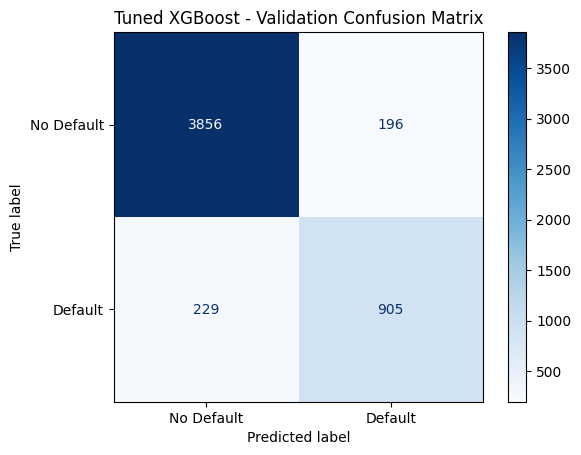

In [83]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_best = confusion_matrix(y_val, y_pred_best)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best,
    display_labels=['No Default', 'Default']
)

disp.plot(cmap='Blues')

plt.title("Tuned XGBoost - Validation Confusion Matrix")
plt.show()

What happened after tuning?
1. False positives decreased from 221 to 196.

The tuned model incorrectly flagged 25 fewer reliable customers as potential defaulters.

That's an improvement.

2. False negatives increased from 222 to 229.

The tuned model missed 7 additional customers who actually defaulted.

That's a small disadvantage.

3. True positives decreased from 912 to 905.

The original model identified seven more actual defaulters.

4. True negatives increased from 3,831 to 3,856.

The tuned model correctly identified 25 more non-defaulters.

. What is our conclusion?
The tuned model has:
- Higher accuracy: 91.80%.
- Higher precision: 82.20%.
- Higher F1-score: 0.8098.
- Slightly lower recall: 79.81%.
- Slightly lower ROC-AUC: 0.9495.

**Find the best classification threshold**

In [84]:
import numpy as np
from sklearn.metrics import precision_recall_curve

# Calculate precision, recall and thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_prob_best
)

# Calculate F1-score for each threshold
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

# Find the threshold with the highest F1-score
best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print("Best threshold:", best_threshold)
print("Best F1-score:", best_f1)

Best threshold: 0.6187324
Best F1-score: 0.8193236714480421


**Apply the new threshold**

In [85]:
# Apply the optimized threshold
y_pred_threshold = (
    y_prob_best >= best_threshold
).astype(int)

print("Predictions using optimized threshold:")
print(y_pred_threshold[:10])

print("\nActual loan status:")
print(y_val.iloc[:10].values)

Predictions using optimized threshold:
[0 0 0 0 0 1 0 0 0 0]

Actual loan status:
[0 0 0 0 0 1 0 1 0 0]


What are we doing?
1. y_prob_best >= best_threshold checks whether each customer's default probability is at least 0.6187.
2. .astype(int) converts True into 1 and False into 0.
3. We store the new predictions in y_pred_threshold.

**Calculate performance using the new threshold**

In [86]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

threshold_metrics = {
    'Accuracy': accuracy_score(y_val, y_pred_threshold),
    'Precision': precision_score(y_val, y_pred_threshold),
    'Recall': recall_score(y_val, y_pred_threshold),
    'F1-score': f1_score(y_val, y_pred_threshold)
}

print(pd.Series(threshold_metrics).round(4))

Accuracy     0.9279
Precision    0.9060
Recall       0.7478
F1-score     0.8193
dtype: float64


1. Accuracy increased: 91.80% → 92.79%
The model now makes more correct predictions overall.

Out of 100 customers, approximately 93 predictions are correct.
2. Precision increased: 82.20% → 90.60%
This is a significant improvement.

Imagine the model predicts 100 customers will default.
- Before threshold optimization, approximately 82 actually defaulted.
- After threshold optimization, approximately 91 actually defaulted.
This means the model is making fewer false alarms.
3. Recall decreased: 79.81% → 74.78%
This is the trade-off.

Imagine there are 100 customers who actually default.
- Before threshold optimization, the model identified approximately 80.
- After threshold optimization, it identifies approximately 75.
Why?

Because we increased the threshold from 0.5 to 0.6187. The model now requires a higher default probability before classifying someone as a defaulter.

Consequently, it misses more actual defaulters.
4. F1-score increased: 0.8098 → 0.8193
Despite the decrease in recall, the improvement in precision was large enough to improve the overall balance.

Our new F1-score is 0.8193.

**Create the confusion matrix using the optimized threshold**

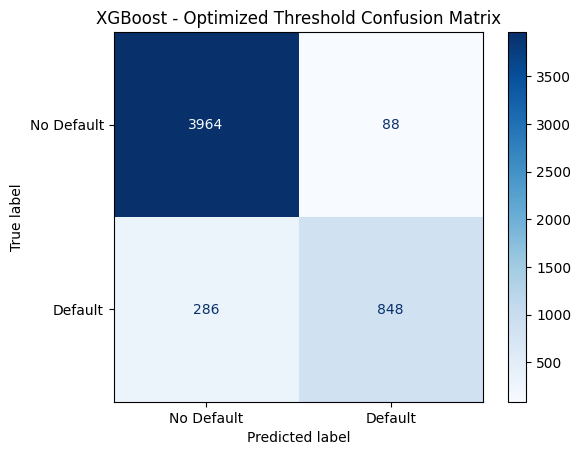

In [87]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_threshold = confusion_matrix(
    y_val,
    y_pred_threshold
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_threshold,
    display_labels=['No Default', 'Default']
)

disp.plot(cmap='Blues')

plt.title("XGBoost - Optimized Threshold Confusion Matrix")
plt.show()


**Model calibration**

Calibration helps us investigate whether predicted probabilities correspond to observed default frequencies.

In [88]:
from sklearn.calibration import CalibratedClassifierCV

calibrated_model = CalibratedClassifierCV(
    estimator=best_model,
    method='sigmoid',
    cv=5
)

In [89]:
# Train the calibrated XGBoost model
calibrated_model.fit(X_fit, y_fit)

print("Calibrated model trained successfully!")

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [05:51:42] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [05:51:42] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [05:51:43] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [05:51:44] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [0

Calibrated model trained successfully!


In [90]:
# Original XGBoost probabilities
y_prob_original = best_model.predict_proba(X_val)[:, 1]

# Calibrated XGBoost probabilities
y_prob_calibrated = calibrated_model.predict_proba(X_val)[:, 1]

print("Original probabilities:")
print(y_prob_original[:10])

print("\nCalibrated probabilities:")
print(y_prob_calibrated[:10])

Original probabilities:
[0.05005262 0.00084273 0.21797909 0.03794355 0.05702744 0.83964086
 0.01186407 0.07052047 0.47671548 0.00891426]

Calibrated probabilities:
[0.02242063 0.01202275 0.05660322 0.01731131 0.02524724 0.87344639
 0.01399496 0.01860424 0.43583003 0.01297003]


**Plot the calibration curves**

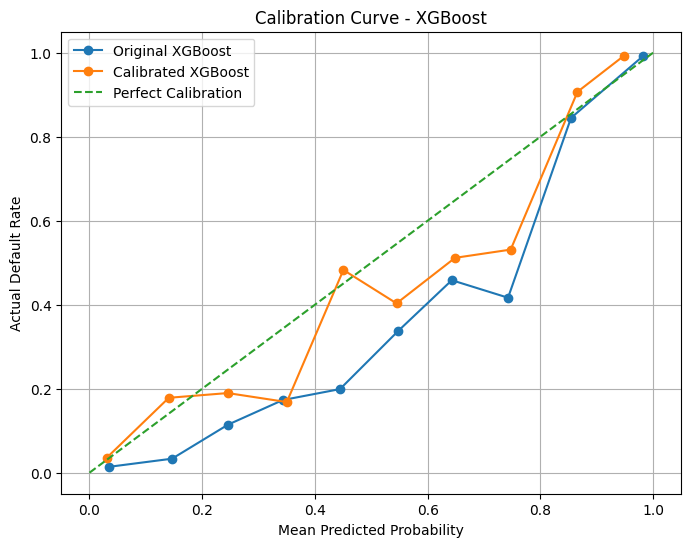

In [91]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Original model calibration
prob_true_original, prob_pred_original = calibration_curve(
    y_val,
    y_prob_original,
    n_bins=10,
    strategy='uniform'
)

# Calibrated model calibration
prob_true_calibrated, prob_pred_calibrated = calibration_curve(
    y_val,
    y_prob_calibrated,
    n_bins=10,
    strategy='uniform'
)

# Plot calibration curves
plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred_original,
    prob_true_original,
    marker='o',
    label='Original XGBoost'
)

plt.plot(
    prob_pred_calibrated,
    prob_true_calibrated,
    marker='o',
    label='Calibrated XGBoost'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Perfect Calibration'
)

plt.xlabel('Mean Predicted Probability')
plt.ylabel('Actual Default Rate')
plt.title('Calibration Curve - XGBoost')
plt.legend()
plt.grid()
plt.show()

Let's compare the two curves.

At lower probabilities:

The orange curve is closer to the ideal line at some points, but not all.

At medium probabilities:

The orange curve is generally closer to the green line in some regions, particularly around 0.5–0.75. However, it still deviates noticeably.

At higher probabilities:

Both curves are relatively close to the ideal line, although there are some differences.
Overall interpretation
The calibrated model appears to improve probability calibration in some ranges, but it does not consistently outperform the original model across all ranges.

Also, the curve is somewhat uneven because customers are divided into 10 probability bins. Some bins may contain fewer customers than others.

We should calculate a numerical metric before deciding whether calibration actually helped.

**Calculate Brier Score**
What is Brier Score?

It measures the difference between predicted probabilities and actual outcomes.

In [92]:
from sklearn.metrics import brier_score_loss

# Original XGBoost Brier Score
brier_original = brier_score_loss(
    y_val,
    y_prob_original
)

# Calibrated XGBoost Brier Score
brier_calibrated = brier_score_loss(
    y_val,
    y_prob_calibrated
)

print("Original Brier Score:", round(brier_original, 4))
print("Calibrated Brier Score:", round(brier_calibrated, 4))

Original Brier Score: 0.0669
Calibrated Brier Score: 0.0563


Your calibrated model has a lower Brier Score, which means its probability predictions have improved according to this metric.

**Compare all model** **versions**

In [93]:
# Add ROC-AUC from the tuned XGBoost model
threshold_metrics['ROC-AUC'] = best_val_metrics['ROC-AUC']

# Create the comparison table again
model_comparison = pd.DataFrame({
    'Logistic Regression': lr_val_metrics,
    'Original XGBoost': xg_val_metrics,
    'Tuned XGBoost': best_val_metrics,
    'Optimized Threshold': threshold_metrics
})

print(model_comparison.round(4))

           Logistic Regression  Original XGBoost  Tuned XGBoost  \
Accuracy                0.8205            0.9146         0.9180   
Precision               0.5660            0.8049         0.8220   
Recall                  0.7681            0.8042         0.7981   
F1-score                0.6517            0.8046         0.8098   
ROC-AUC                 0.8698            0.9555         0.9495   

           Optimized Threshold  
Accuracy                0.9279  
Precision               0.9060  
Recall                  0.7478  
F1-score                0.8193  
ROC-AUC                 0.9495  


What does the comparison tell us?
- Logistic Regression is our baseline model.
- Original XGBoost performs significantly better than Logistic Regression.
- Hyperparameter tuning improves precision and F1-score.
- Threshold optimization further improves accuracy, precision and F1-score, but reduces recall.
Our current preferred model is tuned XGBoost with the 0.6187 threshold, based on the F1-score selection criterion.

**Understand what SHAP does**  So far, we know that our tuned XGBoost model predicts whether a customer is likely to default.

But imagine the bank asks:
- Why did the model classify this customer as high risk?
- Which customer features influenced the prediction?
- Is income more important than loan amount?
- Does a higher interest rate increase the predicted default risk?

In [94]:
!pip install shap


In [95]:
import shap

In [96]:
# Extract the preprocessing component
preprocessor = best_model.named_steps['preprocessor']

# Extract the trained XGBoost classifier
xgb_model = best_model.named_steps['classifier']

# Select 500 validation customers for SHAP analysis
X_shap = X_val.sample(
    n=min(500, len(X_val)),
    random_state=42
)

# Transform the validation data
X_shap_transformed = preprocessor.transform(X_shap)

# Get the transformed feature names
feature_names = preprocessor.get_feature_names_out()

print("Original data shape:", X_shap.shape)
print("Transformed data shape:", X_shap_transformed.shape)
print("Number of features:", len(feature_names))

Original data shape: (500, 11)
Transformed data shape: (500, 26)
Number of features: 26


Why are we doing this?
- named_steps extracts individual components from our pipeline.
- X_shap selects 500 customers to keep SHAP computation manageable.
- preprocessor.transform() applies the same preprocessing learned during training.
- get_feature_names_out() retrieves the names of the features after preprocessing.

**Create the SHAP explainer**
What are we doing?

We're creating a SHAP explainer that understands how our trained XGBoost model makes predictions.

Why are we using TreeExplainer?

XGBoost is a tree-based machine learning algorithm. SHAP provides TreeExplainer, which is designed to explain tree-based models efficiently.

In [97]:
# Create SHAP TreeExplainer
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values
shap_values = explainer(X_shap_transformed)

print("SHAP values calculated successfully!")


SHAP values calculated successfully!


Understand the code
- shap.TreeExplainer(xgb_model) creates an explainer for our trained XGBoost classifier.
- explainer(X_shap_transformed) calculates how each of the 26 features contributes to the predictions for our 500 customers.
- shap_values stores those contributions.

**Create the SHAP Summary (Beeswarm) Plot**

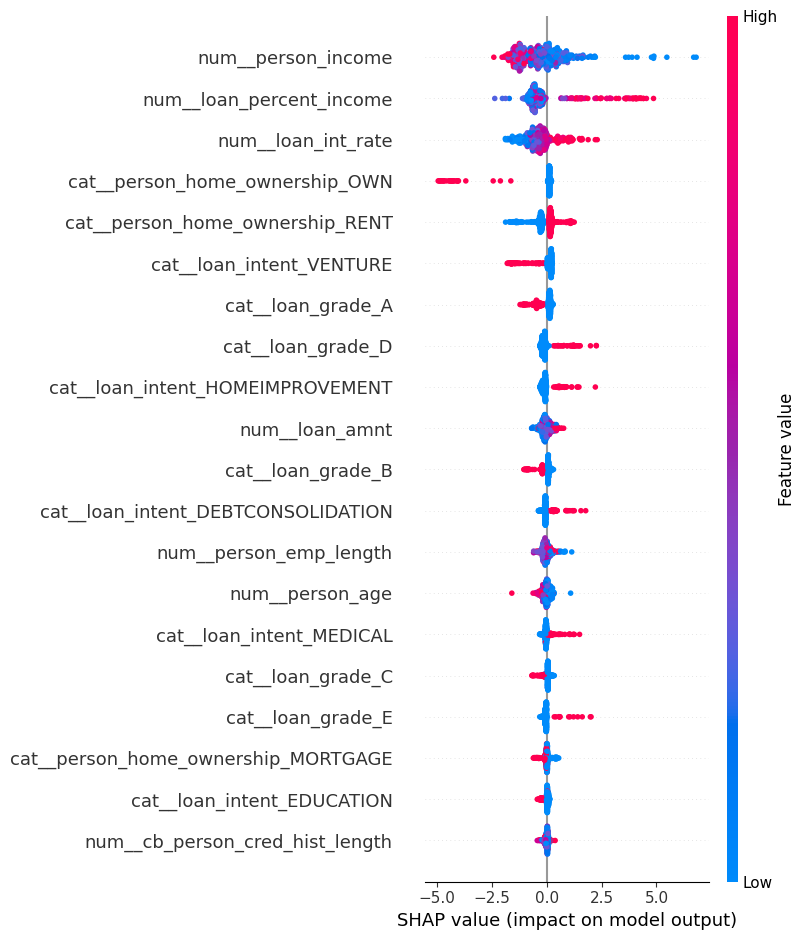

In [98]:
# Create SHAP summary plot
shap.summary_plot(
    shap_values.values,
    X_shap_transformed,
    feature_names=feature_names
)

What is the main finding from your graph?
Your XGBoost model relies most heavily on:
1. Person income.
2. Loan percentage of income.
3. Loan interest rate.
4. Home ownership.
5. Loan intent and loan grade.

1. Person income
Most influential feature
This is the top feature in your graph.

It means customer income has the greatest average influence on the model's predictions among the features analyzed.

The spread of SHAP values also shows that income can influence predictions in both directions.
2. Loan percentage of income
This is the second most important feature.

It represents the proportion of customer income used for the loan.

For example:
- Income = ₹30,000
- Loan amount = ₹15,000
- Loan-to-income ratio = 0.5
A higher ratio can indicate a greater repayment burden.

Your graph shows that higher values (pink) are generally associated with positive SHAP values, pushing predictions towards default.
3. Interest rate
This is the third most influential feature.

Your graph shows higher interest-rate values generally pushing predictions towards default.

A higher interest rate can increase repayment obligations.
4. Home ownership
Two categories appear near the top:
- OWN
- RENT
This means home ownership categories influence the model's predictions.

Remember, these are model-learned relationships, not proof that owning or renting a home causes default.

**Create a SHAP feature importance bar plot**

Create a SHAP Waterfall Plot
So far, we've studied which features influence predictions across 500 customers.

Now let's understand why our model predicted default or no default for one particular customer.

This is called local explainability.

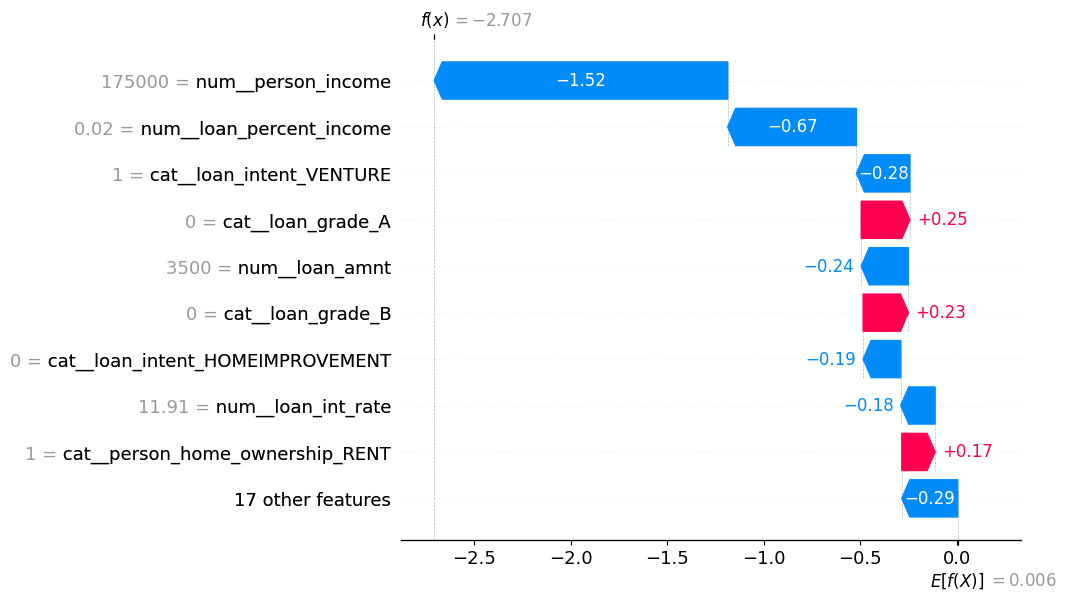

In [100]:
# Select one customer's SHAP explanation
row_index = 5

# Prepare feature values for the waterfall plot
X_shap_dense = (
    X_shap_transformed.toarray()
    if hasattr(X_shap_transformed, "toarray")
    else X_shap_transformed
)

# Create an explanation with feature names
single_explanation = shap.Explanation(
    values=shap_values.values[row_index],
    base_values=shap_values.base_values[row_index],
    data=X_shap_dense[row_index],
    feature_names=feature_names
)

# Display waterfall plot
shap.plots.waterfall(single_explanation)

Understand the important terms
- row_index = 5: Selects the sixth customer from our sample.
- shap_values.values[row_index]: Gets the SHAP contribution of every feature for that customer.
- base_values: The model's starting prediction before considering this customer's individual feature values.
- data: The customer's transformed feature values.
- feature_names: Names the features in the graph.

Let's understand the most important contributions.

1. Person income: -1.52

This is the largest contribution in your graph.

The customer's income is 175,000. This feature pushes the model's prediction strongly towards no default.

2. Loan percent income: -0.67

The customer's loan-to-income ratio is 0.02.

This means the loan amount is relatively small compared with the customer's income. It pushes the prediction towards no default.

3. Loan intent – Venture: -0.28

The customer has venture as the loan purpose.

For this particular customer, the model associates this feature with a lower default prediction.

4. Loan grade A: +0.25

This feature pushes the prediction slightly towards default.

However, its value is 0, meaning this customer does not belong to loan grade A.

5. Loan amount: -0.24

The customer's loan amount is 3,500. This feature pushes the prediction towards no default.

**Create the SHAP Feature Importance Plot**

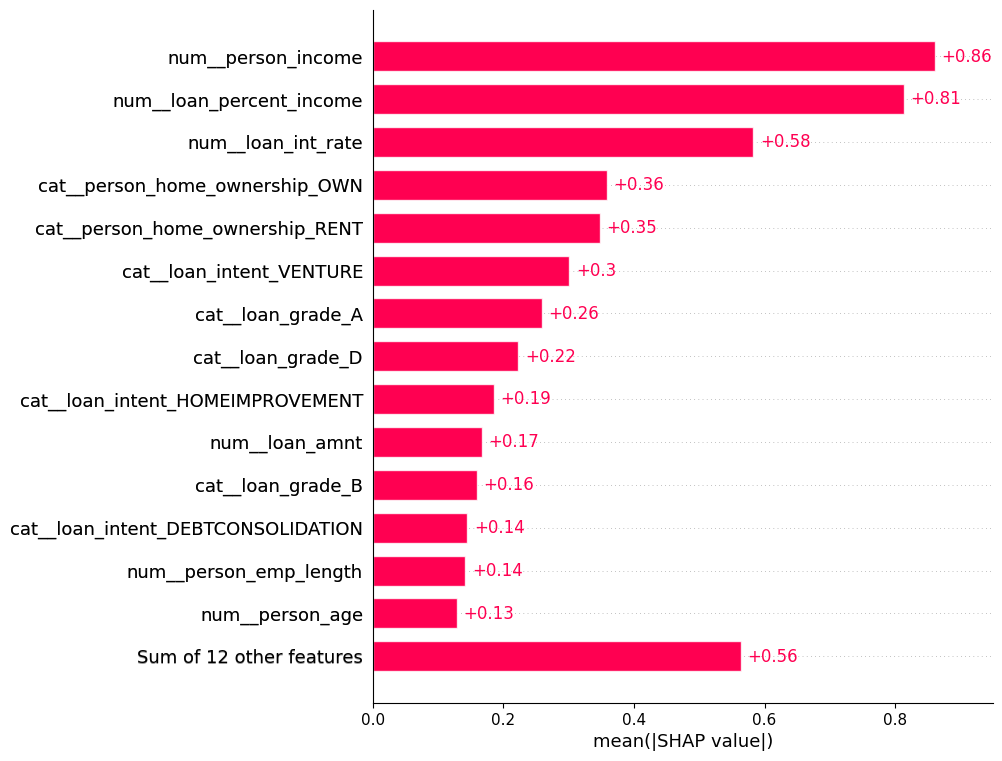

In [101]:
# Create SHAP Explanation with actual feature names
shap_values_named = shap.Explanation(
    values=shap_values.values,
    base_values=shap_values.base_values,
    data=X_shap_dense,
    feature_names=list(feature_names)
)

# Display feature importance
shap.plots.bar(
    shap_values_named,
    max_display=15
)

What does this tell us?
Person income (0.86) is the most influential feature in your model.

Loan percentage of income (0.81) is the second most influential. This indicates that the relationship between a customer's income and loan amount plays a major role in the model's predictions.

Interest rate (0.58) is third. It also has a substantial influence.

Together, these results suggest that your XGBoost model relies heavily on customers' financial characteristics when predicting default risk.

Remember: mean absolute SHAP measures the magnitude of influence, not whether a feature increases or decreases default risk.

What should you remember for interviews?
You can explain your SHAP analysis like this:

"I used SHAP to interpret my tuned XGBoost credit risk model. The global feature importance analysis identified person income, loan-to-income ratio, and loan interest rate as the most influential features. I also used a SHAP waterfall plot to explain individual customer predictions and understand how different features contributed to the predicted default risk."

**Evaluate the model on test data**

enerate final test predictions
Before proceeding, remember our three datasets:
- X_fit: Used to train the model.
- X_val: Used for model selection, tuning and threshold optimization.
- X_test: Kept untouched for final evaluation.

In [102]:
# Generate default probabilities on test data
y_prob_test = best_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
y_pred_test = (
    y_prob_test >= best_threshold
).astype(int)

print("First 10 test predictions:")
print(y_pred_test[:10])

print("\nFirst 10 actual loan statuses:")
print(y_test.iloc[:10].values)

print("\nFirst 10 default probabilities:")
print(y_prob_test[:10])

First 10 test predictions:
[0 0 0 0 1 0 1 0 0 0]

First 10 actual loan statuses:
[0 1 0 0 1 0 1 0 0 0]

First 10 default probabilities:
[0.22181451 0.47188875 0.14621015 0.1389958  0.99790454 0.00108355
 0.9853754  0.02460315 0.0015318  0.01324376]


In [103]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

test_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_test),
    'Precision': precision_score(y_test, y_pred_test),
    'Recall': recall_score(y_test, y_pred_test),
    'F1-score': f1_score(y_test, y_pred_test),
    'ROC-AUC': roc_auc_score(y_test, y_prob_test)
}

print("Final Test Performance:")
print(pd.Series(test_metrics).round(4))

Final Test Performance:
Accuracy     0.9367
Precision    0.9193
Recall       0.7793
F1-score     0.8435
ROC-AUC      0.9514
dtype: float64


Accuracy – 93.67%

The model correctly classified approximately 94 out of every 100 customers.

Precision – 91.93%

Of all customers predicted as defaulters, approximately 92% actually defaulted.

This means relatively few reliable customers are incorrectly flagged.

Recall – 77.93%

Of all customers who actually defaulted, the model identified approximately 78%.

This also means the model missed approximately 22% of actual defaulters.

F1-score – 0.8435

This represents the balance between precision and recall.

ROC-AUC – 0.9514

This indicates excellent ability to distinguish between customers who default and those who do not.

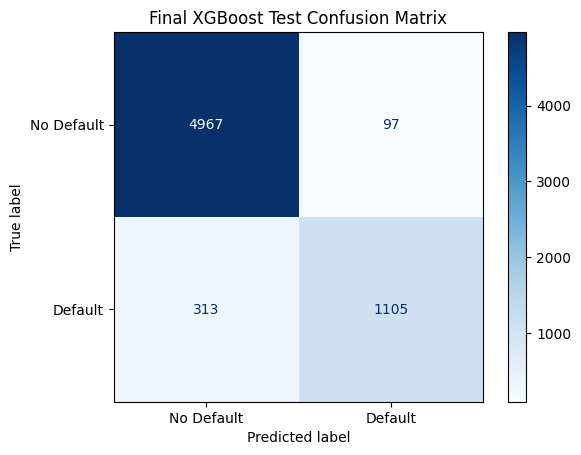

In [104]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_test = confusion_matrix(y_test, y_pred_test)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=['No Default', 'Default']
)

disp.plot(cmap='Blues')

plt.title("Final XGBoost Test Confusion Matrix")
plt.show()

. What do these numbers mean?
- 4,967 True Negatives: The model correctly identified 4,967 customers who did not default.
- 97 False Positives: It incorrectly flagged 97 customers as potential defaulters.
- 313 False Negatives: It failed to identify 313 customers who actually defaulted.
- 1,105 True Positives: It correctly identified 1,105 actual defaulters.

**Save the model**

In [105]:
import joblib

In [125]:

import joblib

# 1. Save tuned XGBoost model
joblib.dump(best_model, 'tuned_xgboost_model.pkl')

# 2. Save calibrated XGBoost model
joblib.dump(calibrated_model, 'calibrated_xgboost_model.pkl')

# 3. Save optimized threshold separately
joblib.dump(best_threshold, 'best_threshold.pkl')

print("All files saved successfully!")


All files saved successfully!
